
# Classificação MILCO/NOMBO com fusão GhostNetV2 + MobileNetV2 (sobre os recortes da detecção YOLO)

Este notebook parte de onde o `sonar_deteccao_comparacao_modelos_V3_AA.ipynb` (Modelos A/B YOLO,
box-only) parou.

## ⚠️ Aviso importante: recorte é necessário

O notebook de detecção **remapeia toda anotação para uma única classe `0 = object`**
(célula "Remapear toda anotação para a classe única `object`") e **não recorta nenhuma imagem** —
ele só treina/avalia localização de caixa. Isso significa que:

- Os `.txt` em `work/yolo_dataset/labels/{train,val,test}/` **não têm mais a classe real
  MILCO/NOMBO** (foram todos virados `0 = object`).
- Nenhum recorte (`.jpg` isolado por objeto) existe ainda em disco.

Então este notebook **inclui a etapa de recorte** como primeiro passo — usando a anotação
**original** (antes do remapeamento) para recuperar a classe real de cada objeto, mas aplicada
**sobre as mesmas imagens que já caíram em train/val/test** na Seção 3 do notebook de detecção
(lidas diretamente de `yolo_dataset/images/{split}/`). Isso garante que a divisão treino/val/teste
da classificação seja **consistente** com a da detecção — nenhuma imagem que foi treino na detecção
vira teste na classificação, ou vice-versa.

## O que este notebook faz

1. Reconstrói os recortes (com a classe real) a partir das anotações originais.
2. Organiza os recortes em `crops_dataset/{train,val,test}/{MILCO,NOMBO}/*.jpg`.
3. Treina o classificador de fusão **GhostNetV2 + MobileNetV2** (mesma estratégia do notebook
   RetinaNet anterior: cada backbone extrai features, concatena, um classificador denso decide
   MILCO ou NOMBO).
4. Avalia (acurácia, precisão, recall, F1, matriz de confusão).
5. Monta o pipeline fim-a-fim: **YOLO (Modelo A ou B, já treinado) → recorte → classificador de
   fusão**, desenhando a caixa + rótulo + confiança na imagem final.


## 1. Imports

In [14]:

# !pip install torch torchvision timm scikit-learn matplotlib pillow ultralytics --quiet

import os
import glob
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms as T

import timm

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)


Dispositivo: cuda



## 2. Configuração — duas pastas separadas

Este notebook usa **duas pastas distintas**, para não misturar o que pertence à detecção (YOLO)
com o que pertence à classificação (GhostNetV2+MobileNetV2):

- **`DETECCAO_DIR`**: a pasta onde o notebook de detecção já rodou — contém `yolo_dataset/`
  (imagens + labels remapeados pra classe única `object`) e `runs/` (pesos `best.pt` dos
  Modelos A/B treinados). **Só leitura** aqui — nada neste notebook escreve dentro dela.
- **`CLASSIFICACAO_DIR`**: a pasta nova onde este notebook (e os artefatos que ele gera) vivem —
  vai receber `crops_dataset/` (os recortes com a classe real) e `checkpoints/` (os pesos do
  classificador de fusão treinado aqui).

`BOX_FORMAT` precisa ser **o mesmo** que você confirmou no diagnóstico visual da Seção 3.1 do
notebook de detecção (`"center"` ou `"corner"`) — senão os recortes saem deslocados.


In [15]:

DETECCAO_DIR = Path("D:/testte/SEPARACAO_MODELS/TESTE_BOX_YOLO/work")   # <-- pasta do notebook de detecção (YOLO)
CLASSIFICACAO_DIR = Path("D:/testte/SEPARACAO_MODELS/TESTE_JUNCAO")      # <-- pasta nova deste notebook

RAW_DATA_DIR = "D:/testte/SEPARACAO_MODELS/raw_data"   # anotações originais (antes do remapeamento)
BOX_FORMAT = "center"                                   # <-- ajuste conforme o diagnóstico visual do outro notebook

YOLO_DIR = DETECCAO_DIR / "yolo_dataset"          # gerado pelo notebook de detecção (só leitura)
CROPS_DIR = CLASSIFICACAO_DIR / "crops_dataset"   # gerado por ESTE notebook
CHECKPOINT_DIR = CLASSIFICACAO_DIR / "checkpoints"  # checkpoints do classificador (não do YOLO)

CLASSIFICACAO_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["MILCO", "NOMBO"]          # 0=MILCO, 1=NOMBO na anotação original
CROP_MARGIN = 0.15                        # 15% de contexto extra ao redor da caixa

FUSION_IMG_SIZE = 224
FUSION_BATCH_SIZE = 16
FUSION_EPOCHS = 40
FUSION_LR = 1e-3

assert YOLO_DIR.exists(), (
    f"Não encontrei {YOLO_DIR}. Rode primeiro o notebook de detecção "
    "(sonar_deteccao_comparacao_modelos_V3_AA.ipynb) até a Seção 3, e confirme se DETECCAO_DIR "
    "aponta para a mesma pasta usada lá (WORK_DIR daquele notebook)."
)



## 3. Recuperando a classe real (MILCO/NOMBO) das anotações originais

`parse_annotation_com_classe` é a mesma lógica do `parse_annotation()` do notebook de detecção,
só que devolve também `classe` (em vez de descartá-la). Indexamos todos os `.txt` originais uma
vez por nome de arquivo (stem), para casar rapidamente com cada imagem que já está em
`yolo_dataset/images/{split}/`.


In [16]:

def parse_annotation_com_classe(txt_path, img_w, img_h, box_format="center"):
    resultados = []
    if not os.path.exists(txt_path):
        return resultados
    with open(txt_path, "r") as f:
        for line in f.read().strip().splitlines():
            if not line.strip():
                continue
            parts = line.strip().split()
            cls = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])

            if box_format == "center":
                xc, yc, bw, bh = x, y, w, h
            elif box_format == "corner":
                bw, bh = w, h
                xc, yc = x + w / 2, y + h / 2
            else:
                raise ValueError("box_format deve ser 'center' ou 'corner'")

            xmin = (xc - bw / 2) * img_w
            xmax = (xc + bw / 2) * img_w
            ymin = (yc - bh / 2) * img_h
            ymax = (yc + bh / 2) * img_h
            resultados.append((cls, xmin, ymin, xmax, ymax))
    return resultados


def indexar_anotacoes_originais(raw_dir):
    txt_paths = glob.glob(os.path.join(raw_dir, "**", "*.txt"), recursive=True)
    return {Path(p).stem: p for p in txt_paths}


indice_anotacoes = indexar_anotacoes_originais(RAW_DATA_DIR)
print(f"{len(indice_anotacoes)} anotações originais indexadas em {RAW_DATA_DIR}")


1170 anotações originais indexadas em D:/testte/SEPARACAO_MODELS/raw_data



## 4. Construindo o dataset de recortes

Para cada imagem já presente em `yolo_dataset/images/{train,val,test}/`, busca a anotação
**original** pelo mesmo nome de arquivo, recorta cada objeto (com margem de contexto) e salva em
`crops_dataset/{split}/{MILCO ou NOMBO}/{stem}_{idx}.jpg` — estrutura pronta para
`torchvision.datasets.ImageFolder`.


In [17]:

def construir_dataset_recortes(yolo_dir, raw_dir, out_dir, box_format="center",
                                margin=CROP_MARGIN, class_names=CLASS_NAMES, tamanho_minimo_px=4):
    yolo_dir, out_dir = Path(yolo_dir), Path(out_dir)
    indice = indexar_anotacoes_originais(raw_dir)

    contagens = {split: {c: 0 for c in class_names} for split in ("train", "val", "test")}
    sem_anotacao_original = []
    classes_invalidas = 0
    recortes_degenerados = 0

    for split in ("train", "val", "test"):
        img_dir = yolo_dir / "images" / split
        if not img_dir.exists():
            continue
        for img_path in sorted(img_dir.glob("*.jpg")):
            stem = img_path.stem
            txt_path = indice.get(stem)
            if txt_path is None:
                sem_anotacao_original.append(stem)
                continue

            img = Image.open(img_path).convert("RGB")
            w, h = img.size
            anotacoes = parse_annotation_com_classe(txt_path, w, h, box_format=box_format)

            for idx, (cls, xmin, ymin, xmax, ymax) in enumerate(anotacoes):
                if cls < 0 or cls >= len(class_names):
                    classes_invalidas += 1
                    continue

                nome_classe = class_names[cls]
                bw, bh = xmax - xmin, ymax - ymin
                xmin_m = xmin - bw * margin
                ymin_m = ymin - bh * margin
                xmax_m = xmax + bw * margin
                ymax_m = ymax + bh * margin

                # Arredonda para inteiro ANTES de cortar (é isso que o PIL faz internamente;
                # comparar só os floats deixa passar caixas de <1px que viram recorte vazio).
                xmin_i = max(0, int(round(xmin_m)))
                ymin_i = max(0, int(round(ymin_m)))
                xmax_i = min(w, int(round(xmax_m)))
                ymax_i = min(h, int(round(ymax_m)))

                # Garante um recorte com pelo menos `tamanho_minimo_px` de largura/altura,
                # expandindo para o lado que ainda cabe na imagem.
                if xmax_i - xmin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (xmax_i - xmin_i)
                    xmin_i = max(0, xmin_i - falta // 2)
                    xmax_i = min(w, xmin_i + tamanho_minimo_px)
                    xmin_i = max(0, xmax_i - tamanho_minimo_px)
                if ymax_i - ymin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (ymax_i - ymin_i)
                    ymin_i = max(0, ymin_i - falta // 2)
                    ymax_i = min(h, ymin_i + tamanho_minimo_px)
                    ymin_i = max(0, ymax_i - tamanho_minimo_px)

                if xmax_i <= xmin_i or ymax_i <= ymin_i:
                    recortes_degenerados += 1
                    continue

                crop = img.crop((xmin_i, ymin_i, xmax_i, ymax_i))
                destino = out_dir / split / nome_classe
                destino.mkdir(parents=True, exist_ok=True)
                crop.save(destino / f"{stem}_{idx}.jpg")
                contagens[split][nome_classe] += 1

    if sem_anotacao_original:
        print(f"AVISO: {len(sem_anotacao_original)} imagens sem anotação original correspondente "
              f"(puladas). Primeiras: {sem_anotacao_original[:5]}")
    if classes_invalidas:
        print(f"AVISO: {classes_invalidas} anotações com índice de classe fora de "
              f"CLASS_NAMES={class_names} (puladas).")
    if recortes_degenerados:
        print(f"AVISO: {recortes_degenerados} anotações geraram caixa vazia mesmo após o ajuste "
              f"mínimo (puladas) — vale checar se BOX_FORMAT ('{box_format}') está correto.")

    return contagens


contagens = construir_dataset_recortes(YOLO_DIR, RAW_DATA_DIR, CROPS_DIR, box_format=BOX_FORMAT)

print("\nDistribuição de recortes por split e classe:")
for split, c in contagens.items():
    total = sum(c.values())
    print(f"  {split:5s} -> {c} (total: {total})")



Distribuição de recortes por split e classe:
  train -> {'MILCO': 312, 'NOMBO': 172} (total: 484)
  val   -> {'MILCO': 50, 'NOMBO': 25} (total: 75)
  test  -> {'MILCO': 75, 'NOMBO': 34} (total: 109)



## 5. Checagem do desbalanceamento

Confirma visualmente a proporção MILCO x NOMBO em cada split (o dataset original tem ~437 MILCO
para ~231 NOMBO — desbalanceado). Esses pesos serão usados na loss do treinamento (Seção 8).


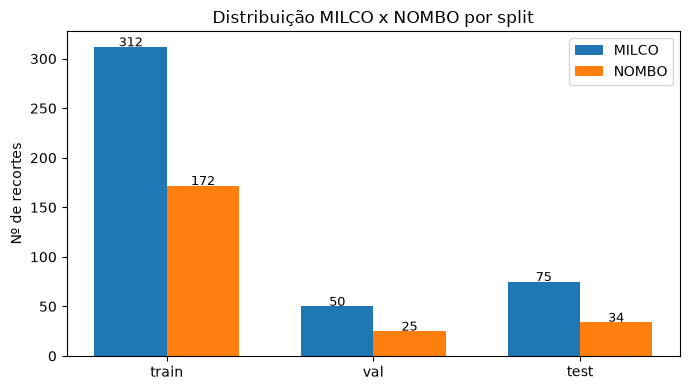

In [18]:

fig, ax = plt.subplots(figsize=(7, 4))
splits = list(contagens.keys())
x = np.arange(len(splits))
largura = 0.35

for i, classe in enumerate(CLASS_NAMES):
    valores = [contagens[s][classe] for s in splits]
    ax.bar(x + i * largura, valores, largura, label=classe)
    for xi, v in zip(x + i * largura, valores):
        ax.text(xi, v + 0.5, str(v), ha="center", fontsize=9)

ax.set_xticks(x + largura / 2)
ax.set_xticklabels(splits)
ax.set_ylabel("Nº de recortes")
ax.set_title("Distribuição MILCO x NOMBO por split")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Datasets e DataLoaders (PyTorch `ImageFolder`)

In [19]:

# ImageFolder ordena as classes alfabeticamente: MILCO (0) antes de NOMBO (1),
# o que coincide com CLASS_NAMES - mas confira o print abaixo para garantir.
transform_train = T.Compose([
    T.Resize((FUSION_IMG_SIZE, FUSION_IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),   # sem flip vertical/rotação livre: a sombra acústica
                                       # do sonar tem direção fixa, preservar essa pista
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

transform_eval = T.Compose([
    T.Resize((FUSION_IMG_SIZE, FUSION_IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

ds_train_cls = datasets.ImageFolder(CROPS_DIR / "train", transform=transform_train)
ds_val_cls   = datasets.ImageFolder(CROPS_DIR / "val", transform=transform_eval)
ds_test_cls  = datasets.ImageFolder(CROPS_DIR / "test", transform=transform_eval)

print("Mapeamento de classes do ImageFolder:", ds_train_cls.class_to_idx)
assert list(ds_train_cls.class_to_idx.keys()) == CLASS_NAMES, (
    "A ordem das classes do ImageFolder não bate com CLASS_NAMES - ajuste CLASS_NAMES "
    "para a ordem mostrada acima antes de continuar."
)

dl_train_cls = DataLoader(ds_train_cls, batch_size=FUSION_BATCH_SIZE, shuffle=True, num_workers=2)
dl_val_cls   = DataLoader(ds_val_cls, batch_size=FUSION_BATCH_SIZE, shuffle=False, num_workers=2)
dl_test_cls  = DataLoader(ds_test_cls, batch_size=FUSION_BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Recortes - treino: {len(ds_train_cls)} | val: {len(ds_val_cls)} | teste: {len(ds_test_cls)}")

# pesos de classe (dataset desbalanceado)
contagem_treino = np.bincount([y for _, y in ds_train_cls.samples], minlength=len(CLASS_NAMES))
pesos_classe = torch.tensor(
    contagem_treino.sum() / (len(CLASS_NAMES) * np.maximum(contagem_treino, 1)),
    dtype=torch.float32
).to(device)
print("Contagem treino:", contagem_treino, "| pesos de classe:", pesos_classe.tolist())


Mapeamento de classes do ImageFolder: {'MILCO': 0, 'NOMBO': 1}
Recortes - treino: 484 | val: 75 | teste: 109
Contagem treino: [312 172] | pesos de classe: [0.7756410241127014, 1.4069766998291016]



## 7. Modelo de fusão GhostNetV2 + MobileNetV2

Cada backbone extrai um vetor de características globais; os dois vetores são concatenados e
passam por um classificador denso — mesma estratégia usada no notebook RetinaNet anterior.


In [20]:

class FusionGhostNetV2MobileNetV2(nn.Module):
    def __init__(self, num_classes=2, freeze_backbones=True, img_size=FUSION_IMG_SIZE):
        super().__init__()

        self.ghostnet = timm.create_model("ghostnetv2_100", pretrained=True, num_classes=0)

        self.mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)
        self.mobilenet.classifier = nn.Identity()

        if freeze_backbones:
            for p in self.ghostnet.parameters():
                p.requires_grad = False
            for p in self.mobilenet.parameters():
                p.requires_grad = False

        # NÃO confiar em atributos como `num_features` para descobrir o tamanho das features:
        # em algumas versões do timm esse valor não bate com o que o forward() de fato devolve
        # (ex.: ghostnetv2_100 reporta 960, mas com num_classes=0 a saída real é 1280, por causa
        # do conv_head extra antes do pooling). Em vez disso, medimos o tamanho real rodando um
        # tensor fake pelos dois backbones uma única vez, na inicialização.
        self.eval()
        with torch.no_grad():
            dummy = torch.zeros(1, 3, img_size, img_size)
            ghost_dim = self.ghostnet(dummy).shape[1]
            mobile_dim = self.mobilenet(dummy).shape[1]
        self.train()

        fused_dim = ghost_dim + mobile_dim
        print(f"[FusionGhostNetV2MobileNetV2] ghost_dim={ghost_dim} mobile_dim={mobile_dim} fused_dim={fused_dim}")

        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def descongelar_backbones(self):
        # libera o fine-tuning das últimas camadas dos dois backbones (chamar após o warmup)
        for p in list(self.ghostnet.parameters())[-20:]:
            p.requires_grad = True
        for p in list(self.mobilenet.features[-4:].parameters()):
            p.requires_grad = True

    def forward(self, x):
        f_ghost = self.ghostnet(x)
        f_mobile = self.mobilenet(x)
        fused = torch.cat([f_ghost, f_mobile], dim=1)
        return self.classifier(fused)


fusion_model = FusionGhostNetV2MobileNetV2(num_classes=len(CLASS_NAMES)).to(device)

n_treinaveis = sum(p.numel() for p in fusion_model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in fusion_model.parameters())
print(f"Parâmetros treináveis: {n_treinaveis:,} / {n_total:,}")


[FusionGhostNetV2MobileNetV2] ghost_dim=1280 mobile_dim=1280 fused_dim=2560
Parâmetros treináveis: 656,130 / 7,755,910



## 8. Treinamento (warmup + fine-tuning)


In [21]:

def treinar_fusion(model, dl_train, dl_val, epochs, lr, pesos_classe=None, nome_checkpoint="fusion_melhor.pt"):
    criterio = nn.CrossEntropyLoss(weight=pesos_classe)
    otimizador = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador, mode="min", factor=0.5, patience=4)

    historico = {"train_loss": [], "val_loss": [], "val_acc": []}
    melhor_val_loss = float("inf")
    paciencia, sem_melhora = 8, 0

    for epoch in range(1, epochs + 1):
        model.train()
        loss_treino = 0.0
        for x, y in dl_train:
            x, y = x.to(device), y.to(device)
            otimizador.zero_grad()
            saida = model(x)
            loss = criterio(saida, y)
            loss.backward()
            otimizador.step()
            loss_treino += loss.item() * x.size(0)
        loss_treino /= len(dl_train.dataset)

        model.eval()
        loss_val, acertos = 0.0, 0
        with torch.no_grad():
            for x, y in dl_val:
                x, y = x.to(device), y.to(device)
                saida = model(x)
                loss = criterio(saida, y)
                loss_val += loss.item() * x.size(0)
                acertos += (saida.argmax(1) == y).sum().item()
        loss_val /= len(dl_val.dataset)
        acc_val = acertos / len(dl_val.dataset)

        scheduler.step(loss_val)
        historico["train_loss"].append(loss_treino)
        historico["val_loss"].append(loss_val)
        historico["val_acc"].append(acc_val)

        print(f"Época {epoch}/{epochs} - loss treino: {loss_treino:.4f} - "
              f"loss val: {loss_val:.4f} - acc val: {acc_val:.4f}")

        if loss_val < melhor_val_loss:
            melhor_val_loss = loss_val
            sem_melhora = 0
            torch.save(model.state_dict(), CHECKPOINT_DIR / nome_checkpoint)
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                print("EarlyStopping acionado.")
                break

    return historico


print(">>> Fase 1: warmup (backbones congelados)")
hist_warmup = treinar_fusion(fusion_model, dl_train_cls, dl_val_cls,
                              epochs=FUSION_EPOCHS // 2, lr=FUSION_LR, pesos_classe=pesos_classe)

print(">>> Fase 2: fine-tuning (últimas camadas dos backbones descongeladas)")
fusion_model.descongelar_backbones()
hist_finetune = treinar_fusion(fusion_model, dl_train_cls, dl_val_cls,
                                epochs=FUSION_EPOCHS // 2, lr=FUSION_LR / 10, pesos_classe=pesos_classe)

fusion_model.load_state_dict(torch.load(CHECKPOINT_DIR / "fusion_melhor.pt", map_location=device))
fusion_model.eval()
print("Melhor checkpoint carregado.")


>>> Fase 1: warmup (backbones congelados)
Época 1/20 - loss treino: 0.6928 - loss val: 0.6574 - acc val: 0.6000
Época 2/20 - loss treino: 0.5784 - loss val: 0.5923 - acc val: 0.6800
Época 3/20 - loss treino: 0.5528 - loss val: 0.5839 - acc val: 0.6667
Época 4/20 - loss treino: 0.5375 - loss val: 0.6258 - acc val: 0.6800
Época 5/20 - loss treino: 0.5149 - loss val: 0.5278 - acc val: 0.7067
Época 6/20 - loss treino: 0.4948 - loss val: 0.5282 - acc val: 0.6933
Época 7/20 - loss treino: 0.5298 - loss val: 0.5467 - acc val: 0.7733
Época 8/20 - loss treino: 0.4724 - loss val: 0.4923 - acc val: 0.7067
Época 9/20 - loss treino: 0.4549 - loss val: 0.4912 - acc val: 0.7600
Época 10/20 - loss treino: 0.4791 - loss val: 0.4967 - acc val: 0.8000
Época 11/20 - loss treino: 0.4759 - loss val: 0.5054 - acc val: 0.7333
Época 12/20 - loss treino: 0.4238 - loss val: 0.5585 - acc val: 0.7467
Época 13/20 - loss treino: 0.3913 - loss val: 0.5915 - acc val: 0.6933
Época 14/20 - loss treino: 0.5114 - loss val

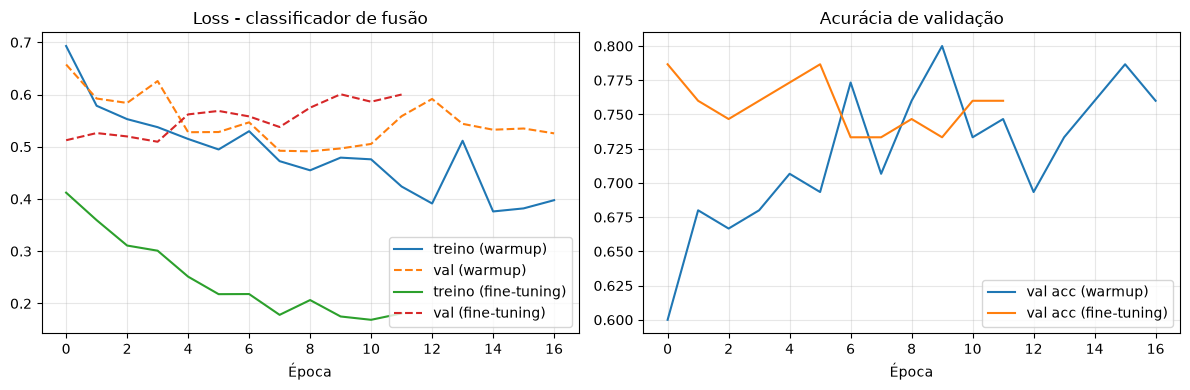

In [22]:

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for hist, nome in [(hist_warmup, "warmup"), (hist_finetune, "fine-tuning")]:
    axs[0].plot(hist["train_loss"], label=f"treino ({nome})")
    axs[0].plot(hist["val_loss"], "--", label=f"val ({nome})")
    axs[1].plot(hist["val_acc"], label=f"val acc ({nome})")

axs[0].set_title("Loss - classificador de fusão")
axs[0].set_xlabel("Época"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].set_title("Acurácia de validação")
axs[1].set_xlabel("Época"); axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Avaliação no conjunto de teste

Acurácia:  0.8532
Precisão:  0.8532
Recall:    0.8532
F1-score:  0.8532

              precision    recall  f1-score   support

       MILCO       0.89      0.89      0.89        75
       NOMBO       0.76      0.76      0.76        34

    accuracy                           0.85       109
   macro avg       0.83      0.83      0.83       109
weighted avg       0.85      0.85      0.85       109



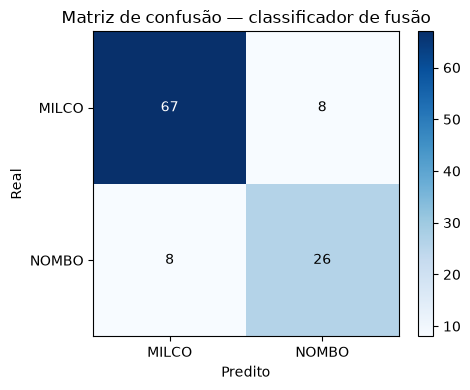

In [23]:

@torch.no_grad()
def avaliar_classificador(model, dl):
    model.eval()
    todos_y, todos_pred = [], []
    for x, y in dl:
        x = x.to(device)
        saida = model(x)
        pred = saida.argmax(1).cpu().numpy()
        todos_pred.extend(pred)
        todos_y.extend(y.numpy())
    return np.array(todos_y), np.array(todos_pred)


y_true, y_pred = avaliar_classificador(fusion_model, dl_test_cls)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")

print(f"Acurácia:  {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predito"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusão — classificador de fusão")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()


## 10. Grade de recortes — real x predito (4x4)

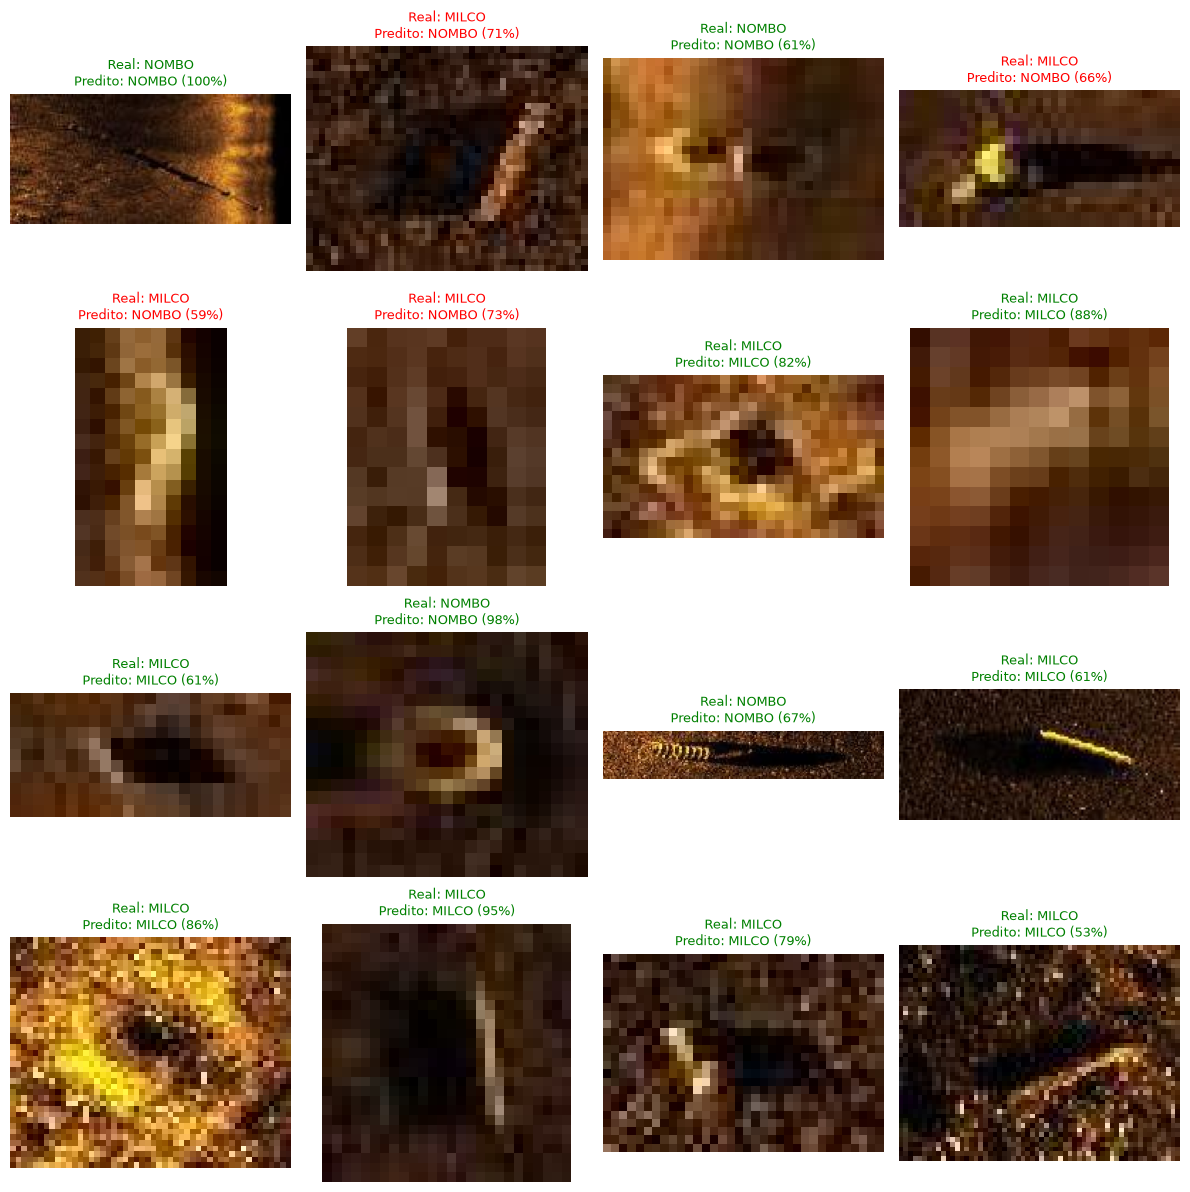

In [24]:

transform_classificacao = transform_eval

@torch.no_grad()
def classificar_recorte(caminho_recorte):
    img = Image.open(caminho_recorte).convert("RGB")
    tensor = transform_classificacao(img).unsqueeze(0).to(device)
    probs = torch.softmax(fusion_model(tensor), dim=1)[0].cpu().numpy()
    idx = int(np.argmax(probs))
    return CLASS_NAMES[idx], float(probs[idx])


def plotar_grade_recortes(dataset, n_linhas=4, n_colunas=4, seed=0):
    rnd = random.Random(seed)
    indices = rnd.sample(range(len(dataset.samples)), min(n_linhas * n_colunas, len(dataset.samples)))

    fig, axs = plt.subplots(n_linhas, n_colunas, figsize=(3 * n_colunas, 3 * n_linhas))
    axs = axs.flatten()

    for ax, idx in zip(axs, indices):
        caminho, classe_real_idx = dataset.samples[idx]
        classe_real = CLASS_NAMES[classe_real_idx]
        classe_predita, confianca = classificar_recorte(caminho)

        img = Image.open(caminho).convert("RGB")
        ax.imshow(img)
        cor = "green" if classe_predita == classe_real else "red"
        ax.set_title(f"Real: {classe_real}\nPredito: {classe_predita} ({confianca*100:.0f}%)",
                     fontsize=9, color=cor)
        ax.axis("off")

    for ax in axs[len(indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


plotar_grade_recortes(ds_test_cls, n_linhas=4, n_colunas=4)



## 11. Pipeline fim-a-fim: YOLO (detecção) + fusão (classificação), com caixa desenhada

Aponte `CAMINHO_PESOS_YOLO` para o `best.pt` do modelo que você escolher (Modelo A ou B, o que
teve melhor `AR_small`/mAP na comparação do outro notebook).


In [30]:

from ultralytics import YOLO

CAMINHO_PESOS_YOLO = Path(r"D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelA_yolo_p2\weights\best.pt") # <-- ajuste
detector = YOLO(CAMINHO_PESOS_YOLO)


@torch.no_grad()
def detectar_e_classificar(imagem_path, score_thresh=0.5, margin=CROP_MARGIN):
    img = Image.open(imagem_path).convert("RGB")
    w, h = img.size

    saida_yolo = detector.predict(source=str(imagem_path), conf=score_thresh, verbose=False)[0]

    resultados = []
    for box in saida_yolo.boxes:
        xmin, ymin, xmax, ymax = box.xyxy[0].tolist()
        score = float(box.conf[0])
        bw, bh = xmax - xmin, ymax - ymin

        xmin_m = max(0, xmin - bw * margin)
        ymin_m = max(0, ymin - bh * margin)
        xmax_m = min(w, xmax + bw * margin)
        ymax_m = min(h, ymax + bh * margin)

        crop = img.crop((xmin_m, ymin_m, xmax_m, ymax_m))
        crop_tensor = transform_classificacao(crop).unsqueeze(0).to(device)
        probs = torch.softmax(fusion_model(crop_tensor), dim=1)[0].cpu().numpy()
        classe_idx = int(np.argmax(probs))

        resultados.append({
            "box": (xmin, ymin, xmax, ymax),
            "score_deteccao": score,
            "classe": CLASS_NAMES[classe_idx],
            "confianca_classificacao": float(probs[classe_idx]),
        })

    return img, resultados


def plotar_resultado(img, resultados, titulo=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                  linewidth=2, edgecolor=cor, facecolor="none")
        ax.add_patch(rect)
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=10, weight="bold",
                bbox=dict(facecolor="black", alpha=0.4, pad=1))
    ax.axis("off")
    if titulo:
        ax.set_title(titulo)
    plt.show()


0001_2015.jpg -> [{'box': (79.6243667602539, 212.3608856201172, 131.77432250976562, 250.9516143798828), 'score_deteccao': 0.9273697137832642, 'classe': 'MILCO', 'confianca_classificacao': 0.9671738147735596}, {'box': (911.7950439453125, 966.5802001953125, 965.6376342773438, 998.6981811523438), 'score_deteccao': 0.7582631707191467, 'classe': 'NOMBO', 'confianca_classificacao': 0.6445120573043823}]
0002_2015.jpg -> [{'box': (174.6575469970703, 296.97747802734375, 184.61927795410156, 312.85565185546875), 'score_deteccao': 0.7918393015861511, 'classe': 'MILCO', 'confianca_classificacao': 0.7136642336845398}, {'box': (324.91204833984375, 401.6396179199219, 345.9027099609375, 412.13671875), 'score_deteccao': 0.7498466372489929, 'classe': 'MILCO', 'confianca_classificacao': 0.9601677060127258}, {'box': (369.9436950683594, 58.97100067138672, 392.19818115234375, 73.10289764404297), 'score_deteccao': 0.710652232170105, 'classe': 'MILCO', 'confianca_classificacao': 0.745939314365387}, {'box': (37

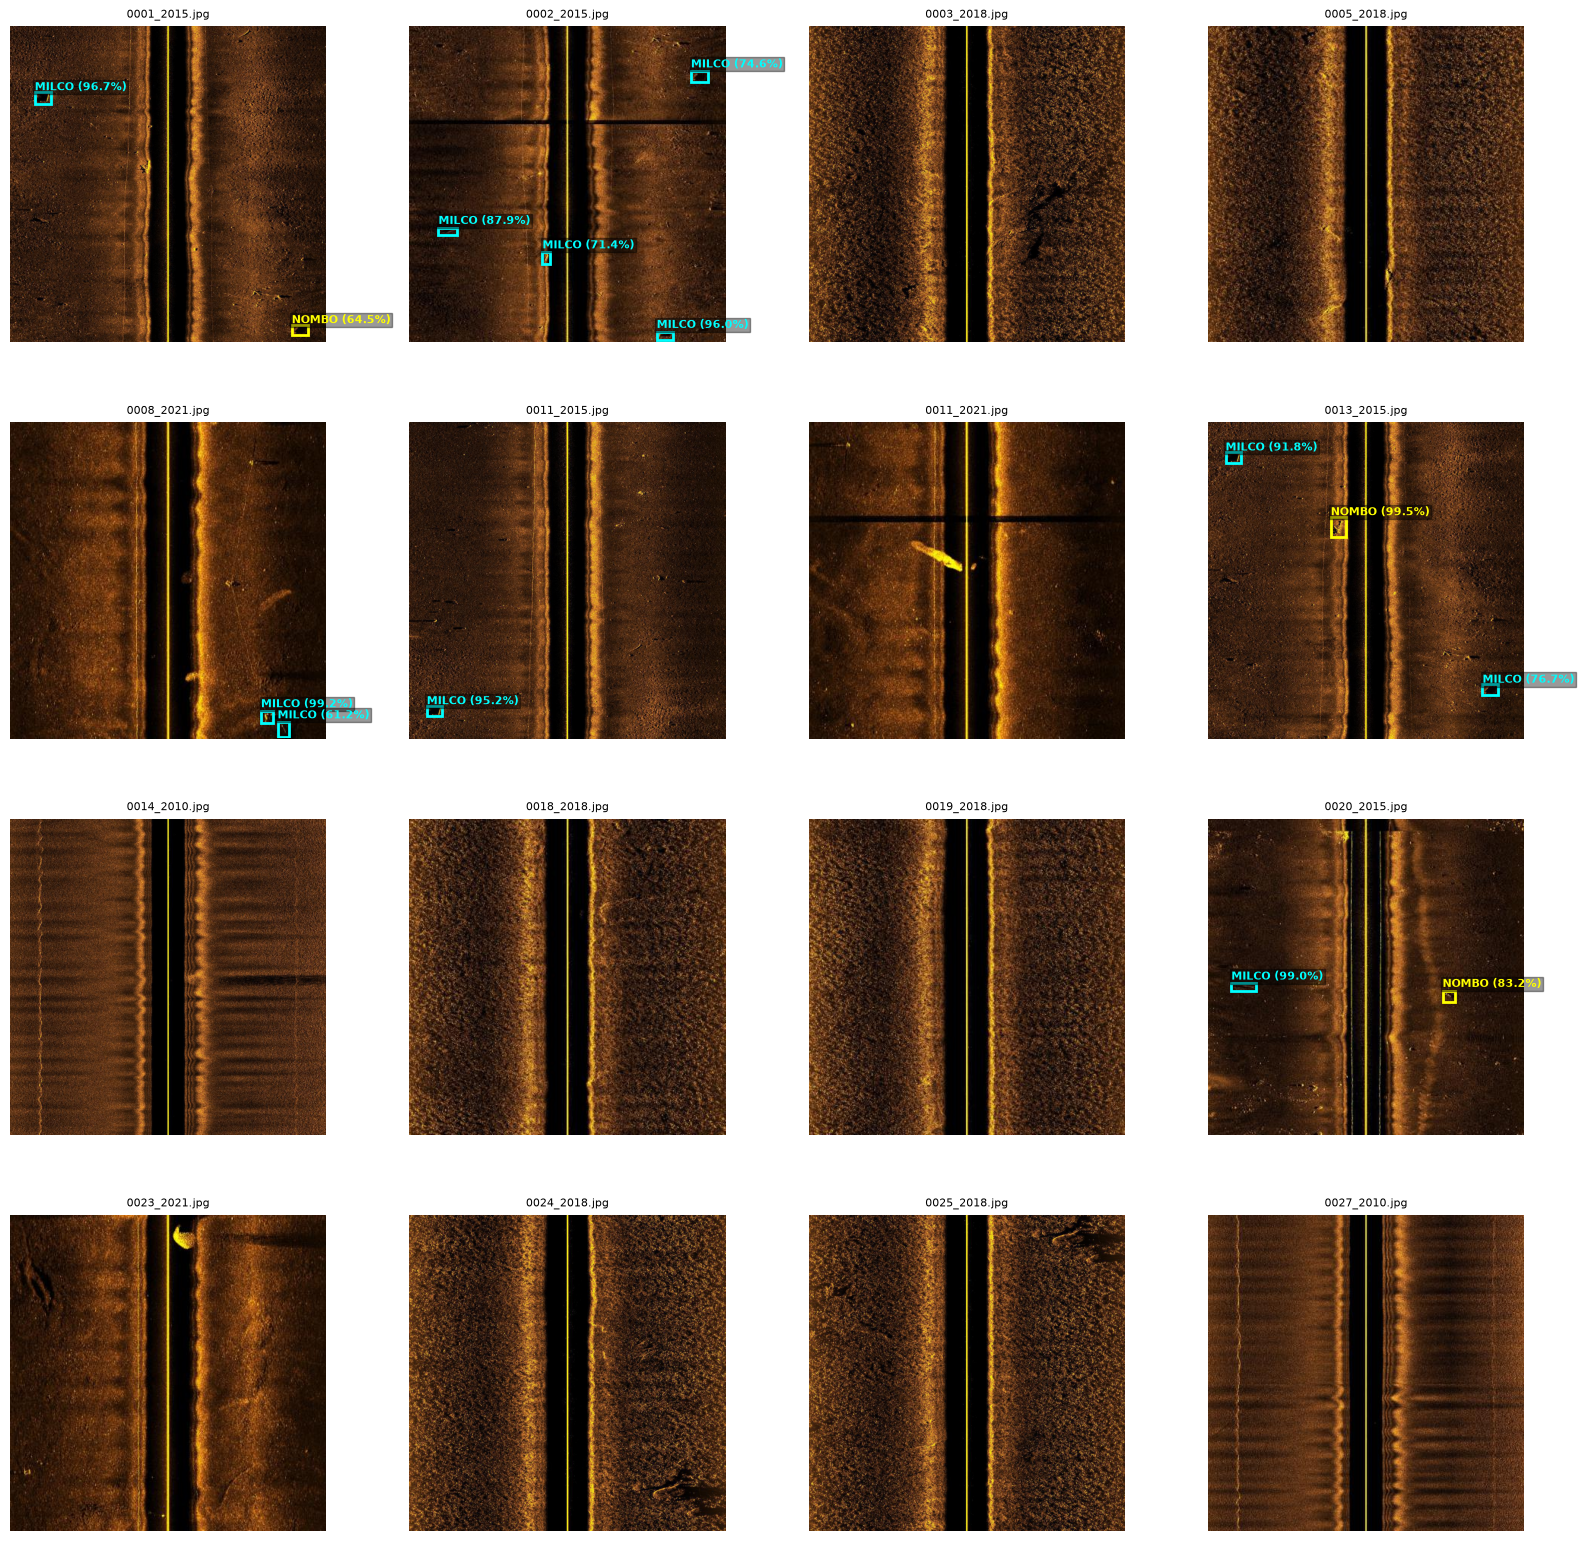

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Ajuste leve na sua função plotar_resultado para aceitar 'ax'
def plotar_resultado(img, resultados, titulo=None, ax=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    
    # Se nenhum eixo for passado, cria uma figura individual (mantém o comportamento original)
    if ax is None:
        fig, ax = plt.subplots(1, figsize=(8, 8))
        mostrar_no_final = True
    else:
        mostrar_no_final = False

    ax.imshow(img)
    
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        
        rect = patches.Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            linewidth=2, edgecolor=cor, facecolor="none"
        )
        ax.add_patch(rect)
        
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(
            xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=8, weight="bold",
            bbox=dict(facecolor="black", alpha=0.4, pad=1)
        )
        
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, fontsize=8)
        
    if mostrar_no_final:
        plt.show()


# 2. Execução da grade 4x4 (16 imagens)
imagens_teste_completas = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))[:16]

# Cria o painel 4x4 de uma só vez
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes_flat = axes.flatten()

for i, img_path in enumerate(imagens_teste_completas):
    img, resultados = detectar_e_classificar(img_path, score_thresh=0.5)
    
    # Passa o eixo específico da grade (axes_flat[i]) para a função desenhar nele
    plotar_resultado(img, resultados, titulo=img_path.name, ax=axes_flat[i])
    print(img_path.name, "->", resultados)

# Desativa eixos vazios caso haja menos de 16 imagens na pasta
for j in range(len(imagens_teste_completas), 16):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.show()